# Dynamic Model in Levels

**Fine-tuned EmbeddingGemma 2 version** of `main/code/04_evaluation.ipynb`: the DoubleMLDeep product embeddings are replaced by [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) embeddings fine-tuned with LoRA and the loss of the DoubleMLDeep model on the training sample (`finetune_gemma.py`, `00_finetune_gemma_colab.ipynb`; text + image, Matryoshka 256 dimensions). Datasets are read from `Gemma-tuned/data`, raw data from `main/data`, outputs are written to `Gemma-tuned/outputs`.

Apart from the parameters below, the check of the estimation sample (cell writing `main_*_keys.csv` in `main/code`), the sensitivity scenarios at the residual shares of the main analysis and the export of the key results at the end, the notebook is identical to `main/code/04_evaluation.ipynb`.

In [1]:
# Parameters (default: fine-tuned EmbeddingGemma 2 text + image embeddings, 256 dimensions)
data_dir = "../data"  # "../../main/data": DoubleMLDeep embeddings as in main/code/04_evaluation.ipynb
txt_only = False  # True: text-only embeddings (datasets from 01_2_create_dataset_txt.ipynb)
emb_dim = 256  # Matryoshka dimension of the fine-tuned EmbeddingGemma 2 embeddings: 256 | 768 (text + image only)
output_dir = "../outputs/04_evaluation"

In [2]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

# Get a colorblind-friendly palette
palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

Path(output_dir).mkdir(parents=True, exist_ok=True)

/tmp/claude-0/-home-user-demand-analysis-repro/8871aba3-e06d-5440-87b8-bf4072e29cf1/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Confidence Level: 90.0%


In [3]:
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
if emb_dim != 256:
    dataframe_name += f"_dim{emb_dim}"
df_full_train = pd.read_csv(f"{data_dir}/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"{data_dir}/{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=342)

In [4]:
print(dataframe_name)

dataset_txt_only_False_embeddings_True


In [5]:
print(df_full_val.shape)
print(df_full_train.shape)

(38041, 342)
(38146, 342)


In [6]:
# same estimation sample as in the main analysis (keys written by main/code/04_evaluation.ipynb)
assert df_full_val[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_val_keys.csv"))
assert df_full_train[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_train_keys.csv"))

In [7]:
df_full_val.isna().sum()

ASIN                    0
date                    0
index                   0
Q_t                     0
PRICE                   0
                       ..
pred_ml_m               0
pred_ml_l_diff          0
pred_ml_m_diff          0
pred_ml_l_diff_lag_1    0
pred_ml_m_diff_lag_1    0
Length: 342, dtype: int64

In [8]:
df_full_train["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [9]:
df_full_val["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [10]:
df_full_train["ASIN"].nunique()

3717

In [11]:
df_full_val["ASIN"].nunique()

3708

In [12]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Names

In [13]:
n_lags = 1

outcome = ["Q_t"]
base_treatment = ["P_bb_t"]
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = [
    "RATING",
    "REVIEW_COUNT",
]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0",
    "similarity_cluster_1",
    "similarity_cluster_2",
    "similarity_cluster_3",
    "similarity_cluster_4",
]

embeddings = [f"emb_{i}" for i in range(emb_dim)]
assert set(embeddings) == {c for c in df_full_val.columns if c.startswith("emb_")}

controls_to_scale = cont_controls + add_controls_to_scale

additional_controls = cont_controls + dummy_controls

## Interactions & CATE Basis

In [14]:
basis_vars = controls_similarities + lag_1_vars
df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=lag_1_vars,
    degree=1,
)
df_basis.head()

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,0.108592,0.004422,-0.119889,0.050719,-0.060219
1,1.0,0.272505,0.653600,0.108592,0.004422,-0.119889,0.050719,-0.060219
2,1.0,0.036240,0.687961,0.108592,0.004422,-0.119889,0.050719,-0.060219
3,1.0,0.025283,0.636881,0.108592,0.004422,-0.119889,0.050719,-0.060219
4,1.0,-0.051370,0.556816,0.108592,0.004422,-0.119889,0.050719,-0.060219


In [15]:
df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=["Q_t-1", "P_bb_t-1"]
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns

Interactions: ['interaction_Q_t-1_intercept', 'interaction_Q_t-1_Q_t-1', 'interaction_Q_t-1_P_bb_t-1', 'interaction_Q_t-1_similarity_cluster_0', 'interaction_Q_t-1_similarity_cluster_1', 'interaction_Q_t-1_similarity_cluster_2', 'interaction_Q_t-1_similarity_cluster_3', 'interaction_Q_t-1_similarity_cluster_4', 'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1', 'interaction_P_bb_t-1_P_bb_t-1', 'interaction_P_bb_t-1_similarity_cluster_0', 'interaction_P_bb_t-1_similarity_cluster_1', 'interaction_P_bb_t-1_similarity_cluster_2', 'interaction_P_bb_t-1_similarity_cluster_3', 'interaction_P_bb_t-1_similarity_cluster_4']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'interaction_Q_t-1_similarity_cluster_3',
       'interaction_Q_t-1_similarity_cluster_4',
       'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1',
       'interaction_P_bb_t-1_P_bb_t-1',
       'interaction_P_bb_t-1_similarity_cluster_0',
       'interaction_P_bb_t-1_similarity_cluster_1',
       'interaction_P_bb_t-1_similarity_cluster_2',
       'interaction_P_bb_t-1_similarity_cluster_3',
       'interaction_P_bb_t-1_similarity_cluster_4'],
      dtype='object', length=358)

## Average Effect

In [16]:
df_dynamic = df_interact_val.copy()

### Linear Models

In [17]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [18]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0027
          coef  std err        t  P>|t|   [5.0%  95.0%]
const  -10.756    0.104 -103.858  0.000 -10.926 -10.586
P_bb_t  -0.111    0.033   -3.384  0.001  -0.164  -0.057


,lower,upper,coef
P_bb_t,-0.164462,-0.056884,-0.110673


In [19]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.5549
          coef  std err       t  P>|t|  [5.0%  95.0%]
const   -9.617    0.144 -66.753  0.000 -9.854  -9.380
P_bb_t  -0.483    0.047 -10.299  0.000 -0.560  -0.406
emb_0   -0.282    0.361  -0.780  0.436 -0.876   0.313
emb_1    0.473    0.391   1.210  0.226 -0.170   1.115
emb_2    0.938    0.392   2.394  0.017  0.293   1.582
...        ...      ...     ...    ...    ...     ...
emb_251  0.072    0.337   0.214  0.830 -0.482   0.626
emb_252 -0.456    0.394  -1.156  0.248 -1.104   0.193
emb_253 -0.247    0.348  -0.711  0.477 -0.819   0.325
emb_254  0.357    0.380   0.939  0.348 -0.269   0.982
emb_255 -0.694    0.390  -1.782  0.075 -1.335  -0.053

[258 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.560002,-0.405764,-0.482883


In [20]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.2213
                                            coef  std err       t  P>|t|  \
const                                    -11.961    0.233 -51.298  0.000   
P_bb_t                                    -0.225    0.031  -7.254  0.000   
RATING_t-1                                 0.222    0.047   4.710  0.000   
REVIEW_COUNT_t-1                           0.000    0.000   5.015  0.000   
New Offer Count: Current                  -0.015    0.006  -2.599  0.009   
Count of retrieved live offers: New, FBA   0.056    0.013   4.217  0.000   
Count of retrieved live offers: New, FBM  -0.033    0.008  -4.285  0.000   
Cars & Race Cars                           0.259    0.057   4.513  0.000   
Trains & Trams                             0.456    0.131   3.473  0.001   
Train Sets                                 0.422    0.077   5.454  0.000   
Trucks                                     0.464    0.064   7.291  0.000   
Tractors                                   0.399    0.131   3.042  

,lower,upper,coef
P_bb_t,-0.275748,-0.173807,-0.224778


In [21]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.6071
                            coef  std err       t  P>|t|   [5.0%  95.0%]
const                    -10.785    0.208 -51.838  0.000 -11.128 -10.443
P_bb_t                    -0.411    0.044  -9.256  0.000  -0.484  -0.338
RATING_t-1                 0.139    0.032   4.326  0.000   0.086   0.192
REVIEW_COUNT_t-1           0.000    0.000   5.414  0.000   0.000   0.000
New Offer Count: Current  -0.003    0.004  -0.642  0.521  -0.010   0.004
...                          ...      ...     ...    ...     ...     ...
emb_251                    0.467    0.305   1.533  0.125  -0.034   0.969
emb_252                   -0.323    0.367  -0.880  0.379  -0.927   0.281
emb_253                   -0.188    0.322  -0.583  0.560  -0.717   0.342
emb_254                    0.362    0.351   1.031  0.302  -0.215   0.940
emb_255                   -0.485    0.370  -1.313  0.189  -1.093   0.123

[286 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.48448,-0.338266,-0.411373


In [22]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.8835
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.677    0.034  -19.935    0.0 -0.733  -0.621
P_bb_t   -0.690    0.040  -17.248    0.0 -0.756  -0.624
Q_t-1     0.936    0.003  321.411    0.0  0.931   0.941
P_bb_t-1  0.678    0.040   16.995    0.0  0.613   0.744


In [23]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.8891
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -1.355    0.061  -22.322  0.000 -1.454  -1.255
P_bb_t   -0.677    0.039  -17.278  0.000 -0.741  -0.612
Q_t-1     0.854    0.006  155.253  0.000  0.845   0.863
P_bb_t-1  0.590    0.039   15.185  0.000  0.526   0.654
emb_0    -0.038    0.062   -0.606  0.544 -0.140   0.065
...         ...      ...      ...    ...    ...     ...
emb_251  -0.016    0.059   -0.278  0.781 -0.114   0.081
emb_252  -0.073    0.068   -1.071  0.284 -0.186   0.039
emb_253   0.070    0.060    1.174  0.240 -0.028   0.168
emb_254   0.045    0.065    0.689  0.491 -0.062   0.152
emb_255  -0.048    0.068   -0.696  0.487 -0.160   0.065

[260 rows x 6 columns]


In [24]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.8929
                                           coef  std err        t  P>|t|  \
const                                    -0.962    0.051  -18.978  0.000   
P_bb_t                                   -0.746    0.039  -18.956  0.000   
Q_t-1                                     0.925    0.003  279.493  0.000   
P_bb_t-1                                  0.722    0.039   18.383  0.000   
RATING_t-1                                0.030    0.007    4.621  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.670  0.000   
New Offer Count: Current                 -0.001    0.001   -1.625  0.104   
Count of retrieved live offers: New, FBA  0.005    0.001    3.398  0.001   
Count of retrieved live offers: New, FBM -0.004    0.001   -3.797  0.000   
Cars & Race Cars                          0.020    0.006    3.371  0.001   
Trains & Trams                            0.052    0.014    3.754  0.000   
Train Sets                                0.032    0.008    4.069  

In [25]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.8976
             coef  std err        t  P>|t|  [5.0%  95.0%]
const      -1.641    0.076  -21.661  0.000 -1.765  -1.516
P_bb_t     -0.720    0.039  -18.674  0.000 -0.784  -0.657
Q_t-1       0.850    0.006  145.392  0.000  0.840   0.860
P_bb_t-1    0.641    0.038   16.729  0.000  0.578   0.704
RATING_t-1  0.031    0.008    3.949  0.000  0.018   0.044
...           ...      ...      ...    ...    ...     ...
emb_251     0.037    0.058    0.651  0.515 -0.057   0.132
emb_252    -0.052    0.067   -0.771  0.441 -0.162   0.059
emb_253     0.080    0.058    1.380  0.168 -0.015   0.176
emb_254     0.043    0.064    0.671  0.502 -0.062   0.147
emb_255    -0.021    0.067   -0.305  0.760 -0.132   0.090

[288 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8938
                                           coef  std err        t  P>|t|  \
const                                    -0.954    0.054  -17.642  0.000   
P_bb_t                                   -0.765    0.039  -19.405  0.000   
Q_t-1                                     0.911    0.004  242.108  0.000   
P_bb_t-1                                  0.681    0.039   17.442  0.000   
similarity_cluster_0                     -0.054    0.102   -0.533  0.594   
similarity_cluster_1                      0.278    0.137    2.021  0.043   
similarity_cluster_2                      0.310    0.114    2.717  0.007   
similarity_cluster_3                      0.251    0.124    2.026  0.043   
similarity_cluster_4                      0.062    0.090    0.686  0.492   
RATING_t-1                                0.037    0.007    5.330  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.827  0.000   
New Offer Count: Current                 -0.001    0.001   -1.015  

In [27]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8944
                                            coef  std err       t  P>|t|  \
const                                     -1.486    0.345  -4.311  0.000   
P_bb_t                                    -0.771    0.040 -19.464  0.000   
interaction_Q_t-1_intercept                0.630    0.031  20.353  0.000   
interaction_Q_t-1_Q_t-1                   -0.013    0.004  -3.331  0.001   
interaction_Q_t-1_P_bb_t-1                -0.049    0.002 -21.193  0.000   
interaction_Q_t-1_similarity_cluster_0    -0.265    0.158  -1.677  0.093   
interaction_Q_t-1_similarity_cluster_1    -0.273    0.213  -1.283  0.199   
interaction_Q_t-1_similarity_cluster_2    -0.203    0.170  -1.191  0.234   
interaction_Q_t-1_similarity_cluster_3    -0.194    0.187  -1.042  0.297   
interaction_Q_t-1_similarity_cluster_4    -0.229    0.142  -1.614  0.107   
interaction_P_bb_t-1_intercept            -0.160    0.009 -17.489  0.000   
interaction_P_bb_t-1_Q_t-1                 0.076    0.013   6.052  

In [28]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

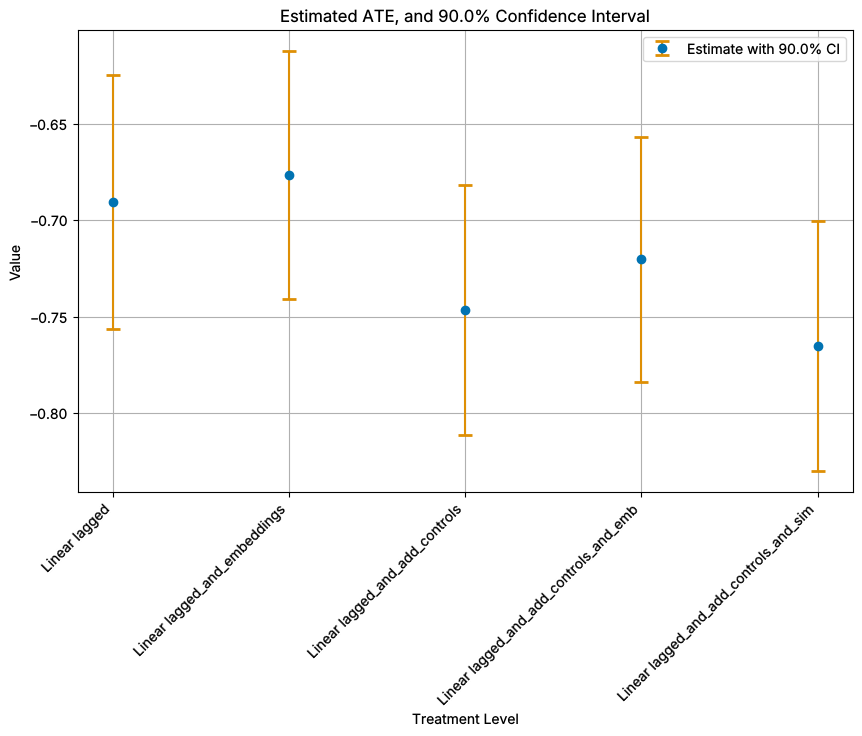

In [29]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"), bbox_inches="tight")
plt.show()

In [30]:
df_base

,lower,upper,coef,model
0,-0.756093,-0.624438,-0.690266,Linear lagged
1,-0.740964,-0.612152,-0.676558,Linear lagged_and_embeddings
2,-0.811127,-0.681600,-0.746364,Linear lagged_and_add_controls
3,-0.783571,-0.656705,-0.720138,Linear lagged_and_add_controls_and_emb
4,-0.830082,-0.700358,-0.765220,Linear lagged_and_add_controls_and_sim


### DML Models

In [31]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [32]:
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=lag_1_vars + embeddings
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.652    0.045 -14.466    0.0 -0.726 -0.578
R2 Outcome: 0.8736 R2 Treatment: 0.9738



In [33]:
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=lag_1_vars + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.812    0.0 -0.758 -0.623
R2 Outcome: 0.8991 R2 Treatment: 0.9775



In [34]:
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=lag_1_vars + embeddings + additional_controls)
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.667    0.046 -14.417    0.0 -0.743 -0.591
R2 Outcome: 0.8986 R2 Treatment: 0.9751



In [35]:
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

         coef  std err      t  P>|t|   5.0%  95.0%
P_bb_t -0.758    0.046 -16.45    0.0 -0.833 -0.682
R2 Outcome: 0.8988 R2 Treatment: 0.9772



In [36]:
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_pca + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.732    0.044 -16.479    0.0 -0.805 -0.659
R2 Outcome: 0.9009 R2 Treatment: 0.9775



### Visualization

In [37]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

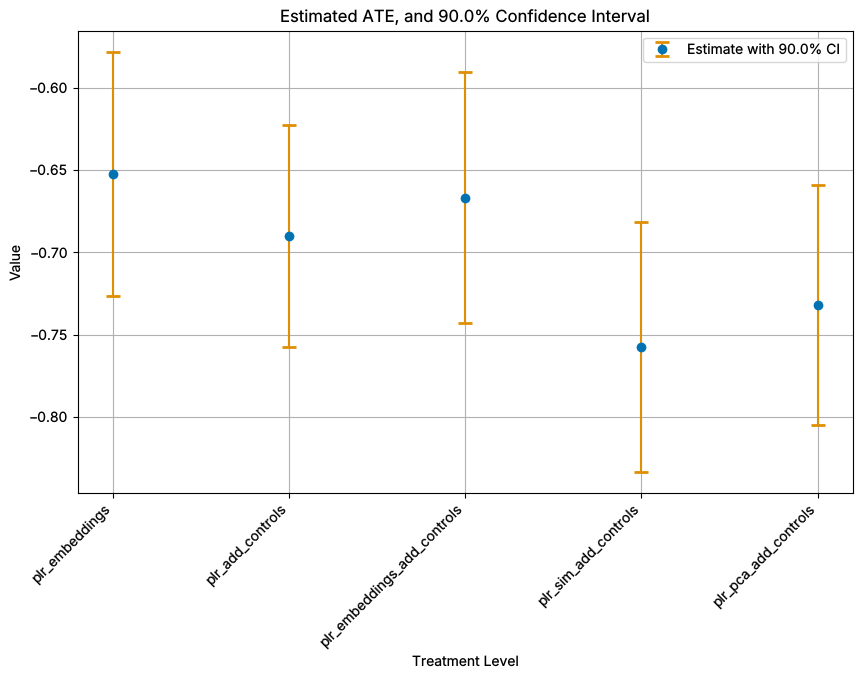

In [38]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"), bbox_inches="tight")
plt.show()

### Main Table of Homogeneous Effects

All rows of the table of estimated inverse-rank elasticities in the paper (Models I-1 to I-3) are taken from the estimation output above: the linear models are re-summarized with the same OLS specification and clustered covariance as in `estimate_linear_model`, the boosted-tree rows are taken from the fitted `DoubleMLPLR` objects. Confidence intervals are two-sided 90% intervals.

In [39]:
def summarize_linear_treatment(controls):
    x = sm.add_constant(df_dynamic[base_treatment + controls])
    results = sm.OLS(df_dynamic[outcome], x).fit(
        cov_type="cluster", cov_kwds={"groups": df_dynamic["ASIN"]}
    )
    ci = results.conf_int(alpha=1 - confidence_level).loc[base_treatment[0]]
    return {
        "coef": results.params[base_treatment[0]],
        "std err": results.bse[base_treatment[0]],
        "t": results.tvalues[base_treatment[0]],
        "P>|t|": results.pvalues[base_treatment[0]],
        "lower": ci.iloc[0],
        "upper": ci.iloc[1],
    }


def summarize_plr_treatment(dml_obj):
    ci = dml_obj.confint(level=confidence_level).iloc[0]
    return {
        "coef": dml_obj.coef[0],
        "std err": dml_obj.se[0],
        "t": dml_obj.t_stat[0],
        "P>|t|": dml_obj.pval[0],
        "lower": ci.iloc[0],
        "upper": ci.iloc[1],
    }


main_table_specs = [
    ("I-1. Linear ($P_{t-1}$, $Q_{t-1}$)", summarize_linear_treatment(lag_1_vars), ci_linear_base_lagged),
    (
        "I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",
        summarize_linear_treatment(lag_1_vars + additional_controls + embeddings),
        ci_linear_base_lagged_add_controls_emb,
    ),
    (
        "I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_linear_treatment(lag_1_vars + controls_similarities + additional_controls),
        ci_linear_base_lagged_add_controls_sim,
    ),
    (
        "I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_linear_treatment(interaction_vars + controls_similarities + additional_controls),
        ci_linear_interactions,
    ),
    (
        "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",
        summarize_plr_treatment(tab_dml_obj_embeddings_add_controls),
        ci_tab_dml_embeddings_add_controls,
    ),
    (
        "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_plr_treatment(tab_dml_obj_sim_add_controls),
        ci_tab_dml_sim_add_controls,
    ),
]

rows = []
for label, row, estimate in main_table_specs:
    # identical to the estimates reported above
    for col in ["coef", "lower", "upper"]:
        assert np.isclose(row[col], np.asarray(estimate[col])[0], rtol=0, atol=1e-12), (label, col)
    rows.append({"specification": label, **row})
df_main_table = pd.DataFrame(rows).set_index("specification")
df_main_table.to_csv(os.path.join(output_dir, "homogeneous_elasticity_estimates.csv"))
df_main_table.round(3)

,coef,std err,t,P>|t|,lower,upper
specification,,,,,,
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$)",-0.690,0.040,-17.248,0.0,-0.756,-0.624
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",-0.720,0.039,-18.674,0.0,-0.784,-0.657
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.765,0.039,-19.405,0.0,-0.830,-0.700
"I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.771,0.040,-19.464,0.0,-0.836,-0.706
"I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",-0.667,0.046,-14.417,0.0,-0.743,-0.591
"I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.758,0.046,-16.450,0.0,-0.833,-0.682


In [40]:
def format_p_value(p):
    return "\\textless 0.001" if p < 0.001 else f"{p:.3f}"


latex_rows = [
    f"{{{label}}} & {r['coef']:.3f} & {r['std err']:.3f} & {r['t']:.3f} & {format_p_value(r['P>|t|'])} "
    f"& {r['lower']:.3f} & {r['upper']:.3f}\\\\"
    for label, r in df_main_table.iterrows()
]
latex_main_table = "\n".join(latex_rows)
with open(os.path.join(output_dir, "homogeneous_elasticity_estimates.tex"), "w") as f:
    f.write(latex_main_table + "\n")
print(latex_main_table)

{I-1. Linear ($P_{t-1}$, $Q_{t-1}$)} & -0.690 & 0.040 & -17.248 & \textless 0.001 & -0.756 & -0.624\\
{I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)} & -0.720 & 0.039 & -18.674 & \textless 0.001 & -0.784 & -0.657\\
{I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.765 & 0.039 & -19.405 & \textless 0.001 & -0.830 & -0.700\\
{I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.771 & 0.040 & -19.464 & \textless 0.001 & -0.836 & -0.706\\
{I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)} & -0.667 & 0.046 & -14.417 & \textless 0.001 & -0.743 & -0.591\\
{I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.758 & 0.046 & -16.450 & \textless 0.001 & -0.833 & -0.682\\


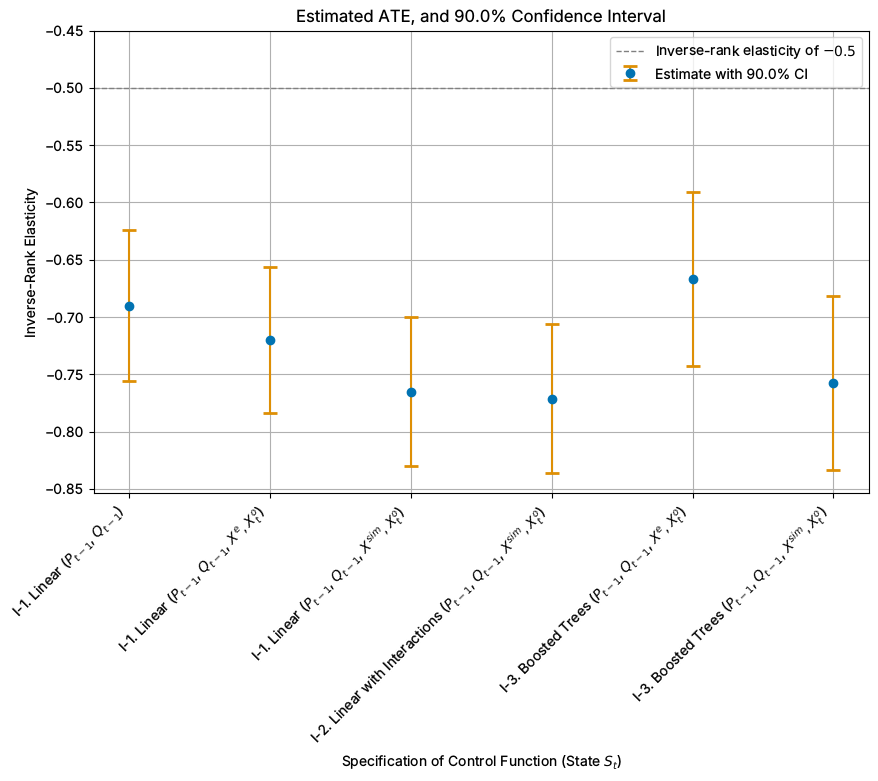

In [41]:
x_vals = np.arange(len(df_main_table))

plt.figure(figsize=(10, 6))
plt.errorbar(
    x_vals,
    df_main_table["coef"],
    yerr=[
        df_main_table["coef"] - df_main_table["lower"],
        df_main_table["upper"] - df_main_table["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)
plt.axhline(-0.5, color="gray", linestyle="--", linewidth=1, label="Inverse-rank elasticity of $-0.5$")
plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Specification of Control Function (State $S_t$)")
plt.xticks(x_vals, df_main_table.index, rotation=45, ha="right")
plt.ylabel("Inverse-Rank Elasticity")
plt.ylim(top=-0.45)
plt.legend(loc="upper right")
plt.grid(True)
plt.savefig(os.path.join(output_dir, "homogeneous_elasticity_estimates.png"), bbox_inches="tight")
plt.show()

## GATEs

0
similarity_cluster_0    5976
similarity_cluster_1    8984
similarity_cluster_2    8327
similarity_cluster_3    8184
similarity_cluster_4    6570
dtype: int64


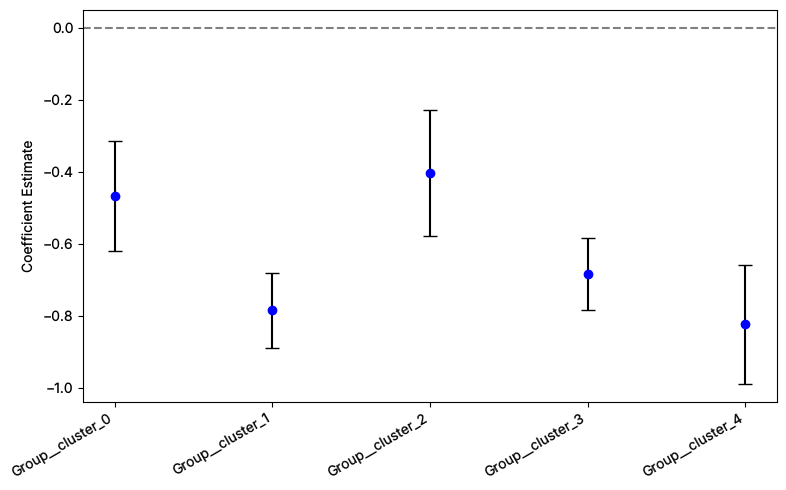

In [42]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs

In [43]:
uniform_ci = True  # False | True

In [44]:
cate_controls = lag_1_vars + embeddings + additional_controls
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls

In [45]:
import gc

gc.collect()

19318

In [46]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.692    0.040 -17.252  0.000 -0.758 -0.626
Q_t-1                -0.175    0.047  -3.713  0.000 -0.252 -0.097
P_bb_t-1              0.023    0.057   0.401  0.688 -0.071  0.117
similarity_cluster_0 -3.550    1.620  -2.192  0.028 -6.214 -0.886
similarity_cluster_1 -5.335    2.139  -2.494  0.013 -8.854 -1.816
similarity_cluster_2 -3.727    1.743  -2.138  0.032 -6.593 -0.860
similarity_cluster_3 -4.453    1.925  -2.313  0.021 -7.620 -1.286
similarity_cluster_4 -3.460    1.462  -2.366  0.018 -5.865 -1.055



Linear specification with interactions
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.704    0.040 -17.605  0.000 -0.769 -0.638
Q_t-1                -0.194    0.046  -4.189  0.000 -0.271 -0.118
P_bb_t-1              0.005    0.058   0.094  0.925 -0.090  0.101
similarity_cluster_0 -3.462    1.616  -2.142  0.032 -6.120 -0.804
similarity_cluster_1 -5.172    2.135  -2.423  0.015 -8.683 -1.661
similarity_cluster_2 -3.596    1.739  -2.068  0.039 -6.456 -0.735
similarity_cluster_3 -4.368    1.921  -2.273  0.023 -7.529 -1.208
similarity_cluster_4 -3.389    1.460  -2.322  0.020 -5.791 -0.988

Tabular DML PLR Specification
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.673    0.046 -14.512  0.000  -0.749 -0.597
Q_t-1                -0.252    0.073  -3.438  0.001  -0.373 -0.131
P_bb_t-1             -0.024    0.035  -0.669  0.503  -0.082  0.034
similarity_cluster_0 -5.025    1.567  -3.208  0.001  -7.602 -2.449


In [47]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.026
Model:                            OLS   Adj. R-squared (uncentered):              0.026
Method:                 Least Squares   F-statistic:                              62.63
Date:                Thu, 22 Oct 2026   Prob (F-statistic):                    1.61e-96
Time:                        00:12:43   Log-Likelihood:                         -20840.
No. Observations:               38041   AIC:                                  4.170e+04
Df Residuals:                   38033   BIC:                                  4.176e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.7037      0.040    -17.605      0.000      -0.782      -0.625
Q_t-1                   -0.1942      0.046     -4.189      0.000      -0.285      -0.103
P_bb_t-1                 0.0055      0.058      0.094      0.925      -0.108       0.119
similarity_cluster_0    -3.4623      1.616     -2.142      0.032      -6.630      -0.295
similarity_cluster_1    -5.1717      2.135     -2.423      0.015      -9.356      -0.988
similarity_cluster_2    -3.5957      1.739     -2.068      0.039      -7.004      -0.187
similarity_cluster_3    -4.3683      1.921     -2.273      0.023      -8.134      -0.602
similarity_cluster_4    -3.3894      1.460     -2.322      0.020      -6.251      -0.528
==============================================================================
Omnibus:                    12177.176   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           693028.435
Skew:                           0.736   Prob(JB):                         0.00
Kurtosis:                      23.858   Cond. No.                         138.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [48]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.030
Model:                            OLS   Adj. R-squared (uncentered):              0.030
Method:                 Least Squares   F-statistic:                              53.33
Date:                Thu, 22 Oct 2026   Prob (F-statistic):                    2.46e-82
Time:                        00:12:43   Log-Likelihood:                         -20346.
No. Observations:               38041   AIC:                                  4.071e+04
Df Residuals:                   38033   BIC:                                  4.078e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6729      0.046    -14.512      0.000      -0.764      -0.582
Q_t-1                   -0.2520      0.073     -3.438      0.001      -0.396      -0.108
P_bb_t-1                -0.0237      0.035     -0.669      0.503      -0.093       0.046
similarity_cluster_0    -5.0255      1.567     -3.208      0.001      -8.096      -1.955
similarity_cluster_1    -7.1074      2.092     -3.397      0.001     -11.208      -3.007
similarity_cluster_2    -5.6525      1.718     -3.290      0.001      -9.020      -2.285
similarity_cluster_3    -6.5206      1.881     -3.467      0.001     -10.207      -2.834
similarity_cluster_4    -4.5326      1.422     -3.187      0.001      -7.320      -1.745
==============================================================================
Omnibus:                    15007.173   Durbin-Watson:                   1.636
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           603299.071
Skew:                           1.203   Prob(JB):                         0.00
Kurtosis:                      22.361   Cond. No.                         238.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [49]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.692 & 0.040 & -17.252 & 0.000 & -0.758 & -0.626 \\
Q_t-1 & -0.175 & 0.047 & -3.713 & 0.000 & -0.252 & -0.097 \\
P_bb_t-1 & 0.023 & 0.057 & 0.401 & 0.688 & -0.071 & 0.117 \\
similarity_cluster_0 & -3.550 & 1.620 & -2.192 & 0.028 & -6.214 & -0.886 \\
similarity_cluster_1 & -5.335 & 2.139 & -2.494 & 0.013 & -8.854 & -1.816 \\
similarity_cluster_2 & -3.727 & 1.743 & -2.138 & 0.032 & -6.593 & -0.860 \\
similarity_cluster_3 & -4.453 & 1.925 & -2.313 & 0.021 & -7.620 & -1.286 \\
similarity_cluster_4 & -3.460 & 1.462 & -2.366 & 0.018 & -5.865 & -1.055 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.704 & 0.040 & -17.605 & 0.000 & -0.769 & -0.638 \\
Q_t-1 & -0.194 & 0.046 & -4.189 & 0.000 & -0.271 & -0.118 \\
P_bb_t-1 & 0.005 & 0.058 & 0.094 & 0.925 & -0.090 & 0.101 \\
similarity_cluster_0 & -3.462 & 1.6

In [50]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.692    0.040 -17.252  0.000 -0.758 -0.626
Q_t-1                -0.175    0.047  -3.713  0.000 -0.252 -0.097
P_bb_t-1              0.023    0.057   0.401  0.688 -0.071  0.117
similarity_cluster_0 -3.550    1.620  -2.192  0.028 -6.214 -0.886
similarity_cluster_1 -5.335    2.139  -2.494  0.013 -8.854 -1.816
similarity_cluster_2 -3.727    1.743  -2.138  0.032 -6.593 -0.860
similarity_cluster_3 -4.453    1.925  -2.313  0.021 -7.620 -1.286
similarity_cluster_4 -3.460    1.462  -2.366  0.018 -5.865 -1.055
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.704    0.040 -17.605  0.000 -0.769 -0.638
Q_t-1                -0.194    0.046  -4.189  0.000 -0.271 -0.118
P_bb_t-1              0.005    0.058   0.094  0.925 -0.090  0.101
similarity_cluster_0 -3.462    1.616  -2.142  0.032 -6.120 -0.804
similarity_cluster_1 -5.172    2.135  -2.423  0.015 -8.683 -1.661
similarity

In [51]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.692162,0.040120,-0.758154,-0.626171
1,Linear Specification,Q_t-1,-0.174882,0.047097,-0.252349,-0.097414
2,Linear Specification,P_bb_t-1,0.022887,0.057069,-0.070983,0.116756
3,Linear Specification,similarity_cluster_0,-3.549946,1.619520,-6.213819,-0.886072
4,Linear Specification,similarity_cluster_1,-5.334838,2.139393,-8.853827,-1.815850
5,Linear Specification,similarity_cluster_2,-3.726655,1.742814,-6.593330,-0.859981
6,Linear Specification,similarity_cluster_3,-4.452665,1.925329,-7.619549,-1.285780
7,Linear Specification,similarity_cluster_4,-3.459848,1.462333,-5.865172,-1.054525
8,Linear Specification (Interactions),intercept,-0.703727,0.039972,-0.769476,-0.637979
9,Linear Specification (Interactions),Q_t-1,-0.194243,0.046368,-0.270512,-0.117974


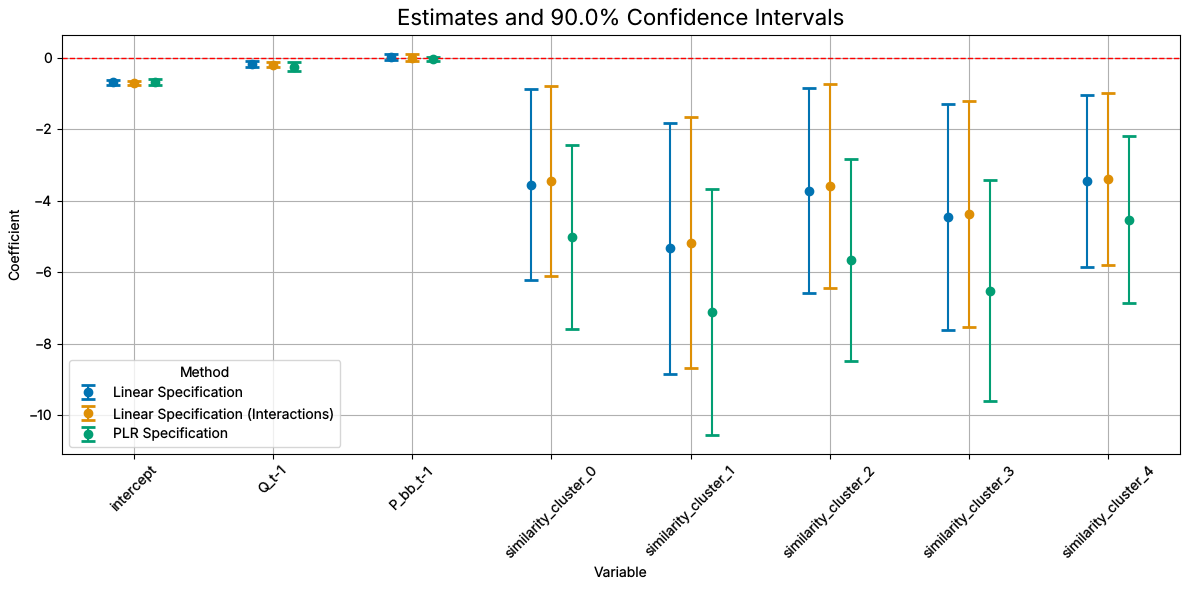

In [52]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### $R^2$

In [53]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)


print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_lvl = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[lag_1_vars])).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_lvl.rsquared)

print("Linear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_interactions_lvl = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[lag_1_vars])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_interactions_lvl.rsquared)

print("PLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_plr_lvl = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[lag_1_vars])).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)
print("Variance explained by lagged variables: ", model_plr_lvl.rsquared)

Linear Specification


Variance explained by embeddings:  0.7237141153424007
Variance explained by similarities:  0.4891309867594352
Variance explained by lagged variables:  0.6209814342345548
Linear Specification with interactions


Variance explained by embeddings:  0.7006064981335867
Variance explained by similarities:  0.4486398413976367
Variance explained by lagged variables:  0.6493956245797448
PLR Specification


Variance explained by embeddings:  0.6823878224394022
Variance explained by similarities:  0.420417704721441
Variance explained by lagged variables:  0.771801677338293


## $\Chi^2$ Test

In [54]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[3, 4, 5, 6, 7]

In [55]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.007566742030158835 (sample size: 38041)
Linear Specification (Interactions) p-value: 0.0075850458029215195 (sample size: 38041)
PLR Specification p-value: 0.0020048846717590774 (sample size: 38041)


In [56]:
het_ids = [1, 2, 3, 4, 5, 6, 7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 3.3821128919697685e-07 (sample size: 38041)
Linear Specification (Interactions) p-value: 7.664077372737665e-08 (sample size: 38041)
PLR Specification p-value: 4.951514802953305e-06 (sample size: 38041)


## Sorted Effects

In [57]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [58]:
df_basis_sorted

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,0.108592,0.004422,-0.119889,0.050719,-0.060219
1,1.0,0.272505,0.653600,0.108592,0.004422,-0.119889,0.050719,-0.060219
2,1.0,0.036240,0.687961,0.108592,0.004422,-0.119889,0.050719,-0.060219
3,1.0,0.025283,0.636881,0.108592,0.004422,-0.119889,0.050719,-0.060219
4,1.0,-0.051370,0.556816,0.108592,0.004422,-0.119889,0.050719,-0.060219
...,...,...,...,...,...,...,...,...
38036,1.0,0.009068,0.478593,-0.175874,0.025211,0.463496,-0.315262,0.005587
38037,1.0,-0.393270,-0.753352,0.289546,-0.225548,-0.206379,0.281893,-0.105796
38038,1.0,-0.277916,-0.753352,0.310173,-0.204578,-0.208795,0.241340,-0.103271
38039,1.0,1.267533,-1.535804,0.049201,-0.512908,-0.103372,0.428698,0.246104


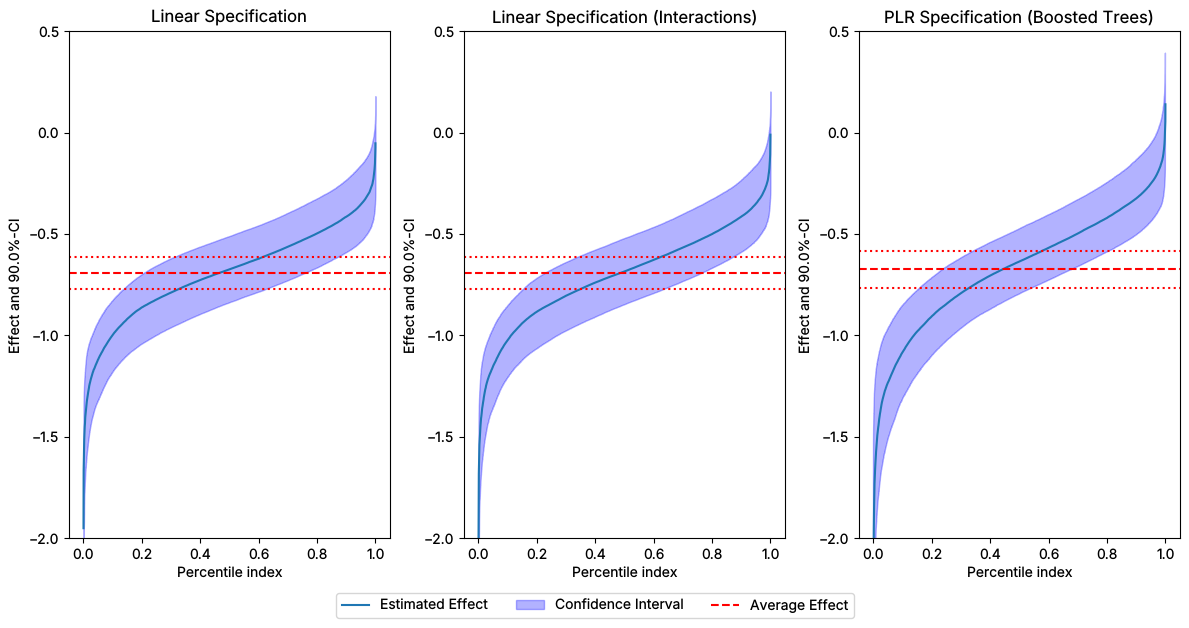

In [59]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1 
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [60]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-1.39432506, -1.29130148, -1.22542342, -1.18563222, -1.15101508,
       -1.12251131, -1.09288345, -1.06616418, -1.04275343, -1.02238305,
       -1.00259932, -0.9855057 , -0.9699191 , -0.95450423, -0.93884879,
       -0.9261636 , -0.91443002, -0.90303281, -0.89256353, -0.88257227,
       -0.87370692, -0.86510495, -0.85725899, -0.84988868, -0.84225671,
       -0.83452345, -0.82681971, -0.81906487, -0.81163169, -0.80376159,
       -0.79680984, -0.79041365, -0.78405793, -0.77692942, -0.77090011,
       -0.76399162, -0.75742854, -0.75109953, -0.74502714, -0.73936824,
       -0.73344979, -0.7276351 , -0.72183105, -0.71637314, -0.71072001,
       -0.70576624, -0.70008829, -0.69503639, -0.68970859, -0.68412702,
       -0.67885511, -0.67284478, -0.66750341, -0.66160182, -0.65571293,
       -0.65006988, -0.64466648, -0.63869019, -0.6327953 , -0.62702544,
       -0.6211752 , -0.61526359, -0.60933575, -0.60378616, -0.59789934,
       -0.59152368, -0.58510769, -0.5789251 , -0.57254109, -0.56

# Sensitivity Analysis

Sensitivity analysis for ATE with PLM model.

In [61]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
        CI lower  theta lower     theta  theta upper  CI upper
P_bb_t -0.852541    -0.795819 -0.666747    -0.537676 -0.475431

------------------ Robustness Values ------------------
        H_0    RV (%)    RVa (%)
P_bb_t  0.0  14.54568  13.011579


In [62]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.02997269]


In [63]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.8986441984365152 R2 Treatment: 0.9751290575323305

R2 Outcome: 0.8735809710644288 R2 Treatment: 0.9737667637773086



In [64]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.19825518027716996
Partial R2 Treatment: 0.05193006853814984


In [65]:
# NEW CHECK

K = rho_hat * np.sqrt(partial_r2_y * partial_r2_d / (1 - partial_r2_d))
scaled_implied_RV = (-K**2 + K*np.sqrt(K**2 + 4)) / 2

print(f"K = {np.squeeze(K):.6f}")
print(scaled_implied_RV.round(4))

K = 0.003123
[0.0031]


In [66]:
# Check

np.sqrt(scaled_implied_RV * scaled_implied_RV / (1 - scaled_implied_RV))

array([0.0031234])

## Calibrated Scenarios

Omitted-confounding scenarios calibrated to the observed-covariate benchmark above: the bias-equivalent equal-strength share $r_0$ (`scaled_implied_RV`, i.e. $r_0/\sqrt{1-r_0} = K$) and its 1.5 and 2 multiples, with $R^2_Y = R^2_D = m\,r_0$ and worst-case alignment $\rho = 1$. Bias bounds $[\theta_-, \theta_+]$ allow for omitted confounding; the confidence bounds additionally account for sampling uncertainty (one-sided at level `confidence_level`, as implemented in DoubleML).

In [67]:
r0 = float(np.squeeze(scaled_implied_RV))
print(f"Calibration r0 = {r0:.8f}")

multipliers = [1.0, 1.5, 2.0]
scenario_names = ["Calibration", "$1.5\\times$ calibration", "$2\\times$ calibration"]

rows = []
for scenario, m in zip(scenario_names, multipliers):
    share = m * r0
    plr_obj.sensitivity_analysis(
        cf_y=share, cf_d=share, rho=1.0, level=confidence_level, null_hypothesis=0.0
    )
    rows.append(
        {
            "scenario": scenario,
            "multiplier": m,
            "share": share,
            "ci_lower": plr_obj.sensitivity_params["ci"]["lower"][0],
            "theta_lower": plr_obj.sensitivity_params["theta"]["lower"][0],
            "theta": plr_obj.coef[0],
            "theta_upper": plr_obj.sensitivity_params["theta"]["upper"][0],
            "ci_upper": plr_obj.sensitivity_params["ci"]["upper"][0],
        }
    )
df_sensitivity_calibrated = pd.DataFrame(rows)
df_sensitivity_calibrated["upper ci < 0"] = df_sensitivity_calibrated["ci_upper"] < 0
df_sensitivity_calibrated["upper ci < -0.5"] = df_sensitivity_calibrated["ci_upper"] < -0.5
df_sensitivity_calibrated.to_csv(os.path.join(output_dir, "sensitivity_calibrated.csv"), index=False)
df_sensitivity_calibrated

Calibration r0 = 0.00311852


,scenario,multiplier,share,ci_lower,theta_lower,theta,theta_upper,ci_upper,upper ci < 0,upper ci < -0.5
0,Calibration,1.0,0.003119,-0.738967,-0.679982,-0.666747,-0.653513,-0.593959,True,True
1,$1.5\times$ calibration,1.5,0.004678,-0.745461,-0.686615,-0.666747,-0.646879,-0.587181,True,True
2,$2\times$ calibration,2.0,0.006237,-0.751966,-0.693259,-0.666747,-0.640236,-0.580391,True,True


In [68]:
# Robustness values (rho = 1): equal-strength share at which the bias bound (RV) or the
# confidence bound (RVa) reaches the null hypothesis
robustness_values = []
for null_hypothesis in [0.0, -0.5]:
    plr_obj.sensitivity_analysis(
        cf_y=r0, cf_d=r0, rho=1.0, level=confidence_level, null_hypothesis=null_hypothesis
    )
    rv = plr_obj.sensitivity_params["rv"][0]
    rva = plr_obj.sensitivity_params["rva"][0]
    robustness_values.append(
        {
            "null_hypothesis": null_hypothesis,
            "RV": rv,
            "RVa": rva,
            "RV / r0": rv / r0,
            "RVa / r0": rva / r0,
        }
    )
df_robustness_values = pd.DataFrame(robustness_values)
df_robustness_values.to_csv(os.path.join(output_dir, "sensitivity_robustness_values.csv"), index=False)
df_robustness_values

,null_hypothesis,RV,RVa,RV / r0,RVa / r0
0,0.0,0.145457,0.130116,46.642841,41.723522
1,-0.5,0.038586,0.024496,12.373011,7.854868


### Scenarios at the Residual Shares of the Main Analysis

The calibrated scenarios above are based on the observed-covariate benchmark of this run. For a comparison of the bounds across embeddings at the same strength of omitted confounding, the bounds are also computed at the residual shares of the calibrated scenarios of the main analysis (DoubleMLDeep embeddings, `main/output/04_evaluation/sensitivity_calibrated.csv`), again with $R^2_Y = R^2_D$ and worst-case alignment $\rho = 1$.

In [69]:
df_main_calibrated = pd.read_csv("../../main/output/04_evaluation/sensitivity_calibrated.csv")

rows = []
for _, scenario in df_main_calibrated.iterrows():
    plr_obj.sensitivity_analysis(
        cf_y=scenario["share"], cf_d=scenario["share"], rho=1.0, level=confidence_level, null_hypothesis=0.0
    )
    rows.append(
        {
            "scenario": scenario["scenario"],
            "multiplier": scenario["multiplier"],
            "share": scenario["share"],
            "ci_lower": plr_obj.sensitivity_params["ci"]["lower"][0],
            "theta_lower": plr_obj.sensitivity_params["theta"]["lower"][0],
            "theta": plr_obj.coef[0],
            "theta_upper": plr_obj.sensitivity_params["theta"]["upper"][0],
            "ci_upper": plr_obj.sensitivity_params["ci"]["upper"][0],
        }
    )
df_sensitivity_main_shares = pd.DataFrame(rows)
df_sensitivity_main_shares["upper ci < 0"] = df_sensitivity_main_shares["ci_upper"] < 0
df_sensitivity_main_shares["upper ci < -0.5"] = df_sensitivity_main_shares["ci_upper"] < -0.5
df_sensitivity_main_shares.to_csv(os.path.join(output_dir, "sensitivity_main_shares.csv"), index=False)
df_sensitivity_main_shares

,scenario,multiplier,share,ci_lower,theta_lower,theta,theta_upper,ci_upper,upper ci < 0,upper ci < -0.5
0,Calibration,1.0,0.015325,-0.790106,-0.732187,-0.666747,-0.601308,-0.540581,True,True
1,$1.5\times$ calibration,1.5,0.022987,-0.822573,-0.765291,-0.666747,-0.568204,-0.506699,True,True
2,$2\times$ calibration,2.0,0.030649,-0.855329,-0.798658,-0.666747,-0.534837,-0.472523,True,False


In [70]:
latex_lines = [
    "\\begin{tabular}{lccccc}",
    "\\toprule",
    " & & \\multicolumn{2}{c}{Bias bounds} & \\multicolumn{2}{c}{Confidence bounds}\\\\",
    "\\cmidrule(lr){3-4}\\cmidrule(lr){5-6}",
    "Scenario & Residual share & Lower & Upper & Lower & Upper\\\\",
    "\\midrule",
]
for _, r in df_sensitivity_calibrated.iterrows():
    latex_lines.append(
        f"{r['scenario']} & {100 * r['share']:.2f}\\% & ${r['theta_lower']:.3f}$ & ${r['theta_upper']:.3f}$ "
        f"& ${r['ci_lower']:.3f}$ & ${r['ci_upper']:.3f}$\\\\"
    )
latex_lines += ["\\bottomrule", "\\end{tabular}"]
latex_sensitivity = "\n".join(latex_lines)
with open(os.path.join(output_dir, "sensitivity_calibrated.tex"), "w") as f:
    f.write(latex_sensitivity + "\n")
print(latex_sensitivity)

\begin{tabular}{lccccc}
\toprule
 & & \multicolumn{2}{c}{Bias bounds} & \multicolumn{2}{c}{Confidence bounds}\\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}
Scenario & Residual share & Lower & Upper & Lower & Upper\\
\midrule
Calibration & 0.31\% & $-0.680$ & $-0.654$ & $-0.739$ & $-0.594$\\
$1.5\times$ calibration & 0.47\% & $-0.687$ & $-0.647$ & $-0.745$ & $-0.587$\\
$2\times$ calibration & 0.62\% & $-0.693$ & $-0.640$ & $-0.752$ & $-0.580$\\
\bottomrule
\end{tabular}


# Export of Key Results

Collects the main estimates of this notebook in `output_dir` (used by `02_cluster_summary.ipynb` and `04_evaluation_comparison.ipynb`).

In [71]:
import json

key_results = {
    "data_dir": data_dir,
    "txt_only": txt_only,
    "emb_dim": emb_dim,
    "dataset": dataframe_name,
    "n_obs": int(len(df_dynamic)),
    "n_products": int(df_dynamic["ASIN"].nunique()),
}

# Linear models (ATE)
ci_linear_interactions["model"] = "Linear interactions"
df_linear = pd.concat([df_base, ci_linear_interactions], ignore_index=True)
df_linear.to_csv(os.path.join(output_dir, "linear_ate_estimates.csv"), index=False)

# PLR models (ATE) and learner R^2
plr_objects = {
    "plr_embeddings": tab_dml_obj_embeddings,
    "plr_add_controls": tab_dml_obj_add_controls,
    "plr_embeddings_add_controls": tab_dml_obj_embeddings_add_controls,
    "plr_sim_add_controls": tab_dml_obj_sim_add_controls,
    "plr_pca_add_controls": tab_dml_obj_pca_add_controls,
}
df_plr = df_averages.copy()
for model_name, obj in plr_objects.items():
    r2_scores = obj.evaluate_learners(metric=r2)
    df_plr.loc[df_plr["model"] == model_name, "std_err"] = obj.se[0]
    df_plr.loc[df_plr["model"] == model_name, "r2_outcome"] = r2_scores["ml_l"][0, 0]
    df_plr.loc[df_plr["model"] == model_name, "r2_treatment"] = r2_scores["ml_m"][0, 0]
df_plr.to_csv(os.path.join(output_dir, "plr_ate_estimates.csv"), index=False)
df_plr

,lower,upper,coef,model,std_err,r2_outcome,r2_treatment
0,-0.726341,-0.578028,-0.652185,plr_embeddings,0.045084,0.873581,0.973767
1,-0.757775,-0.622714,-0.690244,plr_add_controls,0.041056,0.899101,0.977486
2,-0.742816,-0.590679,-0.666747,plr_embeddings_add_controls,0.046247,0.898644,0.975129
3,-0.833361,-0.681851,-0.757606,plr_sim_add_controls,0.046056,0.898827,0.977203
4,-0.805279,-0.659111,-0.732195,plr_pca_add_controls,0.044432,0.900948,0.977479


In [72]:
# GATEs by most similar cluster
df_gates = gates_0_summ.copy()
group_sizes = groups.groupby(0).size()
group_sizes.index = "Group_" + group_sizes.index.astype(str)  # labels used by DoubleMLPLR.gate()
df_gates["n_obs"] = group_sizes.reindex(df_gates.index).values
assert df_gates["n_obs"].notna().all()
df_gates.to_csv(os.path.join(output_dir, "gate_estimates.csv"))

# CATE (best linear predictor) coefficients
cate_summary_df.to_csv(os.path.join(output_dir, "cate_estimates.csv"), index=False)

# Chi^2 tests
chi2_rows = []
for model_name, model in cate_models_polynomial.items():
    chi2_rows.append(
        {
            "model": model_name,
            "p_value_clusters": chi2_test(model, cluster_treatment_ids),
            "p_value_heterogeneity": chi2_test(model, het_ids),
        }
    )
df_chi2 = pd.DataFrame(chi2_rows)
df_chi2.to_csv(os.path.join(output_dir, "chi2_tests.csv"), index=False)

# Variance of the CATE explained by embeddings, similarities and lagged variables
df_var_explained = pd.DataFrame(
    {
        "Linear Specification": [model_lin_emb.rsquared, model_lin_sim.rsquared, model_lin_lvl.rsquared],
        "Linear Specification (Interactions)": [
            model_lin_interactions_emb.rsquared,
            model_lin_interactions_sim.rsquared,
            model_lin_interactions_lvl.rsquared,
        ],
        "PLR Specification": [model_plr_emb.rsquared, model_plr_sim.rsquared, model_plr_lvl.rsquared],
    },
    index=["embeddings", "similarities", "lagged variables"],
)
df_var_explained.to_csv(os.path.join(output_dir, "cate_variance_explained.csv"))
df_chi2

,model,p_value_clusters,p_value_heterogeneity
0,Linear Specification,0.007567,3.382113e-07
1,Linear Specification (Interactions),0.007585,7.664077e-08
2,PLR Specification,0.002005,4.951515e-06


In [73]:
# Per-observation CATEs (as in ../output/04_evaluation/sorted_effects.csv)
df_sorted_effects = df_dynamic[["ASIN", "date"]].copy()
df_sorted_effects["SortEff_lin"] = df_lin_ci_pointwise["effect"].values
df_sorted_effects["SortEff_tab_dml"] = df_tab_dml_ci_pointwise["effect"].values
df_sorted_effects["SortEff_deep_dml"] = df_deep_dml_ci_pointwise["effect"].values
df_sorted_effects.to_csv(os.path.join(output_dir, "sorted_effects.csv"), index=False)

# Sensitivity analysis (calibrated scenarios and robustness values are written above)
plr_obj.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0, level=0.9, null_hypothesis=0.0)
key_results["sensitivity"] = {
    "theta": float(plr_obj.coef[0]),
    "theta_lower_cf003": float(plr_obj.sensitivity_params["theta"]["lower"][0]),
    "theta_upper_cf003": float(plr_obj.sensitivity_params["theta"]["upper"][0]),
    "ci_lower_cf003": float(plr_obj.sensitivity_params["ci"]["lower"][0]),
    "ci_upper_cf003": float(plr_obj.sensitivity_params["ci"]["upper"][0]),
    "rv": float(plr_obj.sensitivity_params["rv"][0]),
    "rva": float(plr_obj.sensitivity_params["rva"][0]),
    "implied_rho": float(np.squeeze(rho_hat)),
    "partial_r2_outcome": float(partial_r2_y),
    "partial_r2_treatment": float(partial_r2_d),
    "scaled_implied_rv": float(np.squeeze(scaled_implied_RV)),
    "K": float(np.squeeze(K)),
}
key_results["sorted_effects_quantiles"] = {
    col: df_sorted_effects[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(6).tolist()
    for col in ["SortEff_lin", "SortEff_tab_dml", "SortEff_deep_dml"]
}
with open(os.path.join(output_dir, "key_results.json"), "w") as f:
    json.dump(key_results, f, indent=2)
print(json.dumps(key_results, indent=2))

{
  "data_dir": "../data",
  "txt_only": false,
  "emb_dim": 256,
  "dataset": "dataset_txt_only_False_embeddings_True",
  "n_obs": 38041,
  "n_products": 3708,
  "sensitivity": {
    "theta": -0.6667474908202535,
    "theta_lower_cf003": -0.7958192170107247,
    "theta_upper_cf003": -0.5376757646297824,
    "ci_lower_cf003": -0.8525410064184787,
    "ci_upper_cf003": -0.4754314550137791,
    "rv": 0.14545679597524938,
    "rva": 0.13011578514557667,
    "implied_rho": 0.029972690500088415,
    "partial_r2_outcome": 0.19825518027716996,
    "partial_r2_treatment": 0.05193006853814984,
    "scaled_implied_rv": 0.0031185235331902647,
    "K": 0.003123397530427271
  },
  "sorted_effects_quantiles": {
    "SortEff_lin": [
      -1.118354,
      -0.82264,
      -0.673549,
      -0.529769,
      -0.353415
    ],
    "SortEff_tab_dml": [
      -1.151015,
      -0.842257,
      -0.684127,
      -0.534433,
      -0.350396
    ],
    "SortEff_deep_dml": [
      -1.23033,
      -0.844351,
      -